<a href="https://colab.research.google.com/github/gulgom1227-coder/2026_2S_phonology/blob/main/07_Speech_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Audio Processing

## 1. Phonological Rules

### 1. Assimilation
Assimilation occurs when a sound becomes more similar to a neighboring sound.

ex) miss you
/mɪs juː/ → /mɪʃuː/

* Constriction Location
- /s/: alveolar
- /ʃ/: palato-alveolar
- /j/: palatal

The pronunciation of /s/ may change to /ʃ/ under the influence of the following /j/.

### 2. Dissimilation
Dissimilation occurs when a sound becomes less similar to another sound.

ex) fifth
/fɪfθ/ → /fɪft/ (in some varieties of English)

* Constriction Degree
- /f/: fricative
- /θ/: fricative
- /t/: stop

### 3. Insertion
Insertion occurs when an additional sound appears between existing sounds.

ex) prince
- /prɪns/ → /prɪnts/

* Constriction Degree
- /n/: stop
- /t/: stop
- /s/: fricative

* Larynx
- /n/: voiced (on)
- /t/: voiceless (off)
- /s/: voiceless (off)

* Velum
- /n/: nasal (on)
- /t/: oral (off)
- /s/: oral (off)

### 4. Deletion
Deletion occurs when a sound is omitted during pronunciation.

ex) next day
- /nɛkst deɪ/ -> /nɛks deɪ/

* Four consecutive consonants
- /k/ + /s/ + /t/ + /d/

## 2. Practice

In [ ]:
# 1. Create a function that takes an audio file name as input and displays its spectrogram. def 활용
# (You do not need to display the waveform.)

In [ ]:
# 2. Use your function to generate spectrograms for different audio files.

In [10]:
def spec_gram(file):
 import librosa
 import numpy as np
 import matplotlib.pyplot as plt

 audio, sr = librosa.load(file)



 pre_audio = librosa.effects.preemphasis(audio)

 n_fft = 2048
 win_length = int(sr * 0.005)
 hop_length = int(sr * 0.001)
 stft_result = librosa.stft(
    pre_audio,
    n_fft=n_fft,
    win_length=win_length,
    hop_length=hop_length
 )
 magnitude = np.abs(stft_result)

 spec_db = librosa.amplitude_to_db(magnitude, ref=np.max(magnitude))
 plt.figure(figsize=(13, 3))

 librosa.display.specshow(
    spec_db,
    sr=sr,
    hop_length=hop_length,
    x_axis="time",
    y_axis="linear",
    cmap="gray_r",
    vmin=-40,
    vmax=0
 )


 plt.ylim(0, 5000)
 plt.xlim(0, len(audio) / sr)
 plt.grid(axis="y")
 plt.xlabel("Time (s)")
 plt.ylabel("Frequency (Hz)")
 #return plt.show() 아니면 spec_db 아니면 아예 없어도 됨.


#전체 선택해서 tab키 한번 누르면 다같이 들여쓰기 됨.

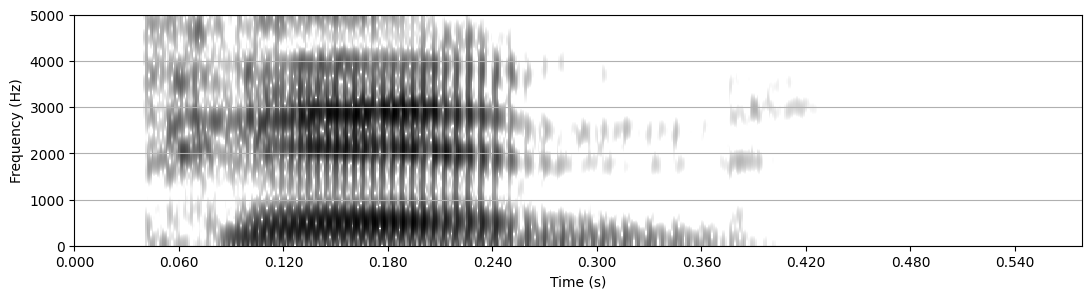

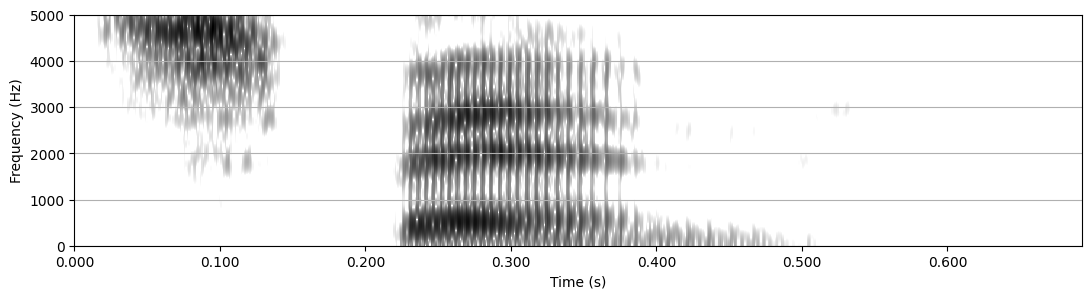

In [15]:
spec_gram("pin (1).wav") # 그래프 상에서 p의 스펙이 다르게 나타남>> 변이음의 증거. formant나타나기 전에 파트가 기식.
spec_gram("spin.wav") #unaspiration. 바로 모음이 나타남.

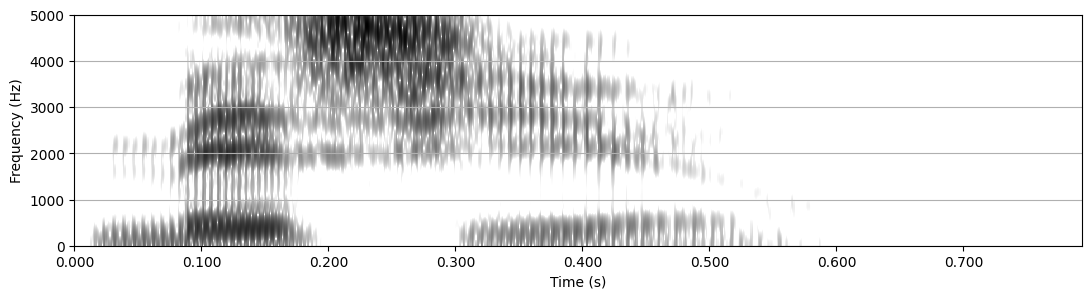

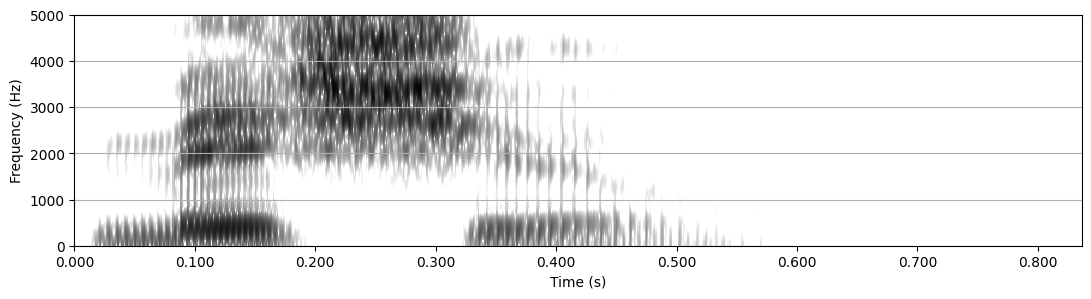

In [16]:
spec_gram("miss_you.wav")
spec_gram("miss_you_assimilated.wav")

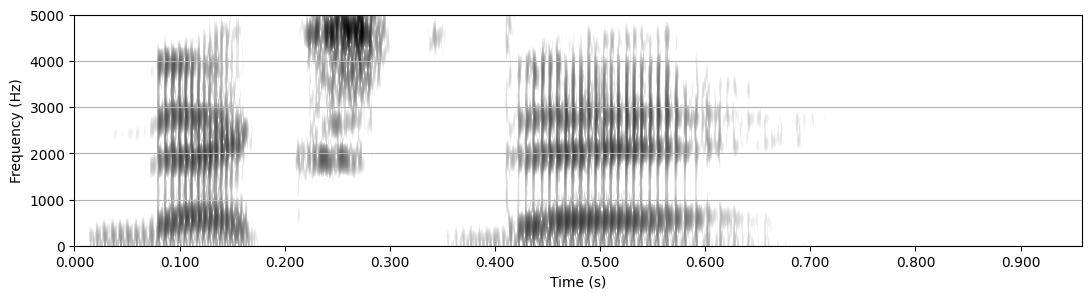

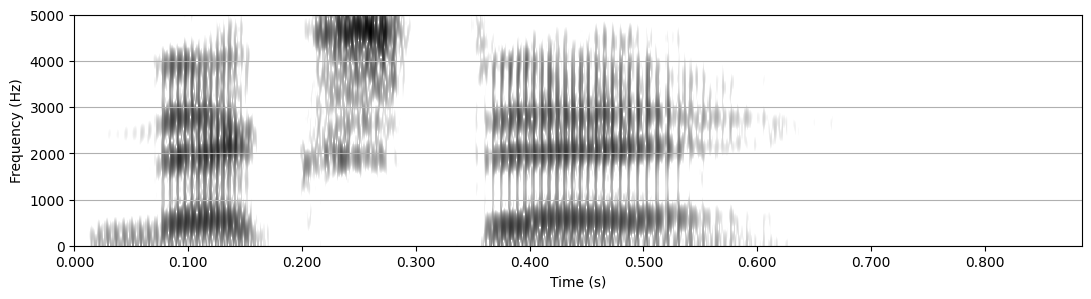

In [17]:
spec_gram("next_day.wav")
spec_gram("next_day_deleted.wav") #공백이 작아짐 >> 음운의 탈락 때문